# Task 2: Heart Failure Analysis 

Questions
1. What is the mortality rate due to heart failure among the study's participants?
2. How are the different variables (age, gender, presence of diabetes or high blood pressure, etc.) distributed in the dataset?
3. How do the variables relate to each other?
4. Is the smoker distribution the same for both genders?
5. How many patients present each combination of underlying health conditions (anaemia only, diabetes only, anaemia + diabetes, etc.)?
6. etc.
7. What are the main factors that are related to a higher risk of heart failure?
8. (Optional) Build a simple machine learning classification model that predicts if a patient is at risk of dying from heart failure.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix


In [3]:
# read and check data
heart = pd.read_csv("heart_failure.csv")
heart.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [4]:
print(f"rows: {heart.shape[0]}")
print(f"columns: {heart.shape[1]}")

rows: 299
columns: 13


In [5]:
heart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [6]:
# round to 2 dicimals
heart.describe().round(2)

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00
mean,60.83,0.43,581.84,0.42,38.08,0.35,263358.03,1.39,136.63,0.65,0.32,130.26,0.32
std,11.89,0.50,970.29,0.49,11.83,0.48,97804.24,1.03,4.41,0.48,0.47,77.61,0.47
min,40.00,0.00,23.00,0.00,14.00,0.00,25100.00,0.50,113.00,0.00,0.00,4.00,0.00
25%,51.00,0.00,116.50,0.00,30.00,0.00,212500.00,0.90,134.00,0.00,0.00,73.00,0.00
50%,60.00,0.00,250.00,0.00,38.00,0.00,262000.00,1.10,137.00,1.00,0.00,115.00,0.00
75%,70.00,1.00,582.00,1.00,45.00,1.00,303500.00,1.40,140.00,1.00,1.00,203.00,1.00
max,95.00,1.00,7861.00,1.00,80.00,1.00,850000.00,9.40,148.00,1.00,1.00,285.00,1.00


In [7]:
# check missing value
for column in heart.columns:
    missing_ratio = heart[column].isna().mean()
    print(f"{column} missing ratio: {missing_ratio:}")

age missing ratio: 0.0
anaemia missing ratio: 0.0
creatinine_phosphokinase missing ratio: 0.0
diabetes missing ratio: 0.0
ejection_fraction missing ratio: 0.0
high_blood_pressure missing ratio: 0.0
platelets missing ratio: 0.0
serum_creatinine missing ratio: 0.0
serum_sodium missing ratio: 0.0
sex missing ratio: 0.0
smoking missing ratio: 0.0
time missing ratio: 0.0
DEATH_EVENT missing ratio: 0.0


There's no missing value so don't need to do replacement.

In [8]:
# binary varialbles
binary_cols = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking']

# continuous variables
continuous_cols = ['age', 'creatinine_phosphokinase', 'ejection_fraction',
                   'platelets', 'serum_creatinine', 'serum_sodium', 'time']

# classification by died or not
survived = heart[heart['DEATH_EVENT'] == 0]
died = heart[heart['DEATH_EVENT'] == 1]

## Q1. What is the mortality rate? 

mortality_rate = death_count / total

In [9]:
total = heart.shape[0]
death_count = heart['DEATH_EVENT'].sum()
survived_count = total - death_count
mortality_rate = death_count / total
survival_rate = survived_count / total
print(f"Total patients: {total}")
print(f"Died: {death_count}")
print(f"Survived: {survived_count}")
print(f"Mortality rate: {mortality_rate:.2%}")
print(f"Survival rate: {survival_rate:.2%}")

Total patients: 299
Died: 96
Survived: 203
Mortality rate: 32.11%
Survival rate: 67.89%


The mortality rate is 32.11%.

## Q2. How are the variables distributed? 

### 2.1 Binary variables 



In [10]:
# rename binary variable
binary_labels = {
    'anaemia': ['No', 'Yes'],
    'diabetes': ['No', 'Yes'],
    'high_blood_pressure': ['No', 'Yes'],
    'sex': ['Female', 'Male'],
    'smoking': ['No', 'Yes']
}


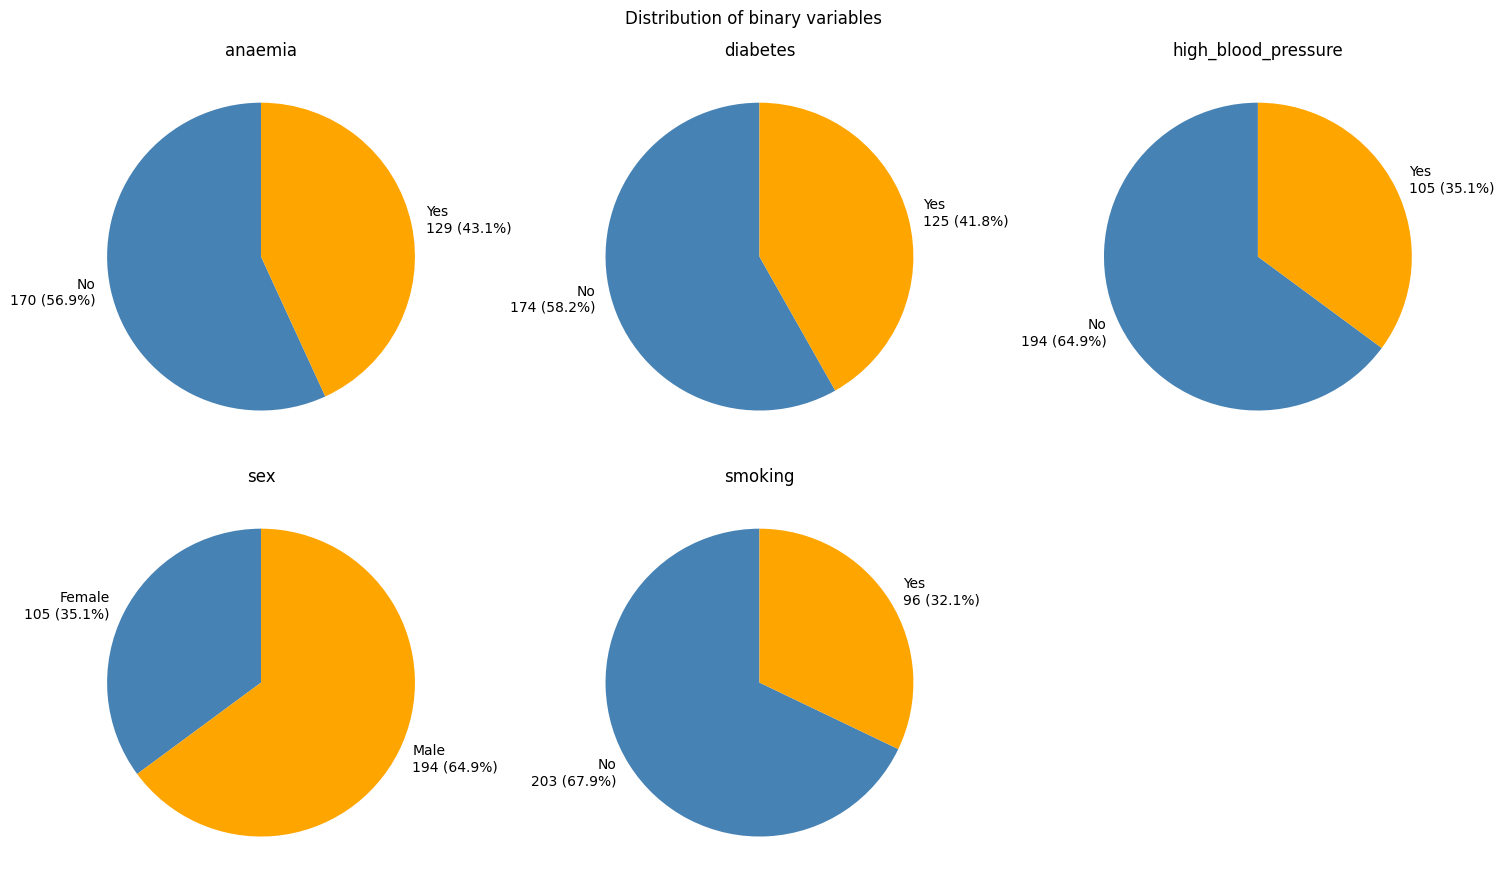

In [11]:
# pie charts for binary variables: 3 plots per row
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()    # make those subplots into a row

for i in range(len(binary_cols)):
    col = binary_cols[i]
    count_1 = heart[col].sum()       # number of yes
    count_0 = total - count_1        # number of no
    percent_0 = count_0 / total        # percent of no
    percent_1 = count_1 / total        # percent of yes

    label_0 = f"{binary_labels[col][0]}\n{count_0} ({percent_0:.1%})"
    label_1 = f"{binary_labels[col][1]}\n{count_1} ({percent_1:.1%})"

    axes[i].pie([count_0, count_1], labels=[label_0, label_1],
                colors=['steelblue', 'orange'], startangle=90)
    axes[i].set_title(col)

# delete last one
fig.delaxes(axes[5])

plt.suptitle('Distribution of binary variables')
plt.tight_layout()
plt.show()

### 2.2 Continuous variables 

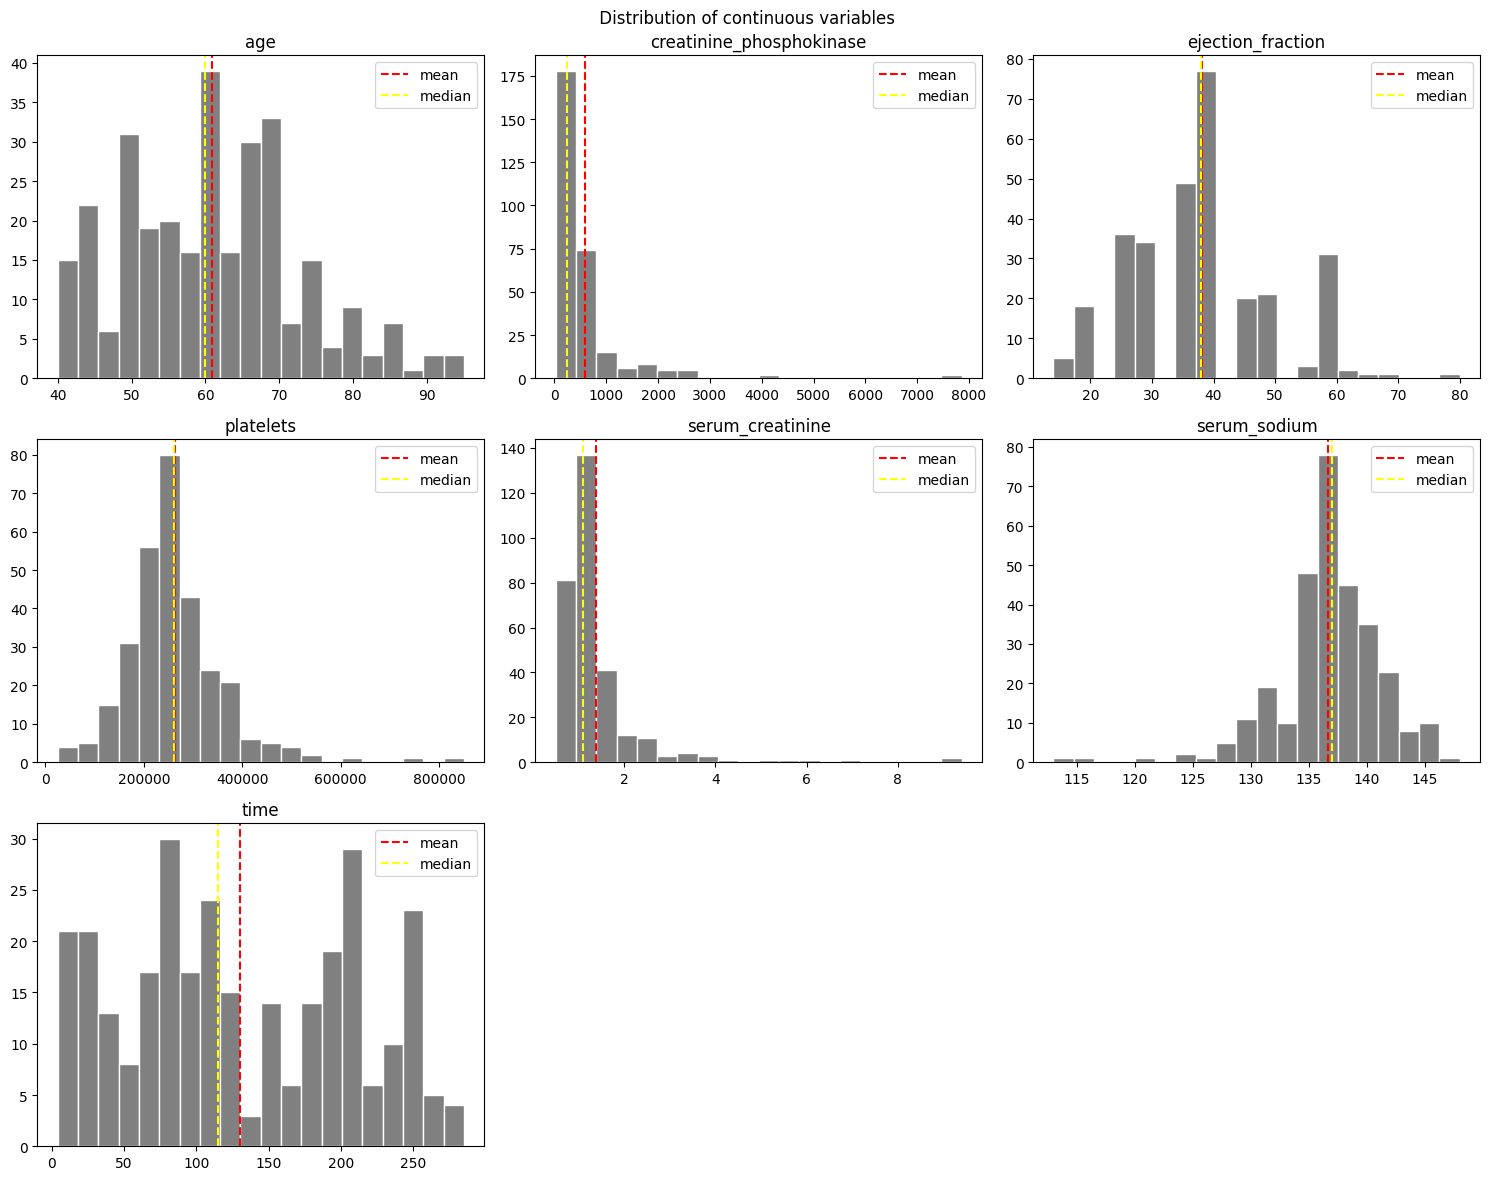

In [12]:
# 3*3
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()   
for i in range(len(continuous_cols)):
    col = continuous_cols[i]
    axes[i].hist(heart[col], bins=20, color='grey', edgecolor='white')
    axes[i].axvline(heart[col].mean(), color='red', linestyle='--', label='mean')
    axes[i].axvline(heart[col].median(), color='yellow', linestyle='--', label='median')
    axes[i].set_title(col)
    axes[i].legend()

# delete last two empty subplots
fig.delaxes(axes[7])
fig.delaxes(axes[8])

plt.suptitle(' Distribution of continuous variables')
plt.tight_layout()
plt.show()

binary：

male65%, female35%。

anaemia 43%，diabetes42%，high blood pressure35%，smoking 32%

continuous：

age：most are older people

ejection fraction：about 38%, normal people 50%-70%，so most patients' ejection fraction decreases

creatinine_phosphokinase and serum_creatinine：right skrewed

serum_sodium：little left skrewed

platelets：symmetry

time：from 4 to 285, very spread out

## Q3. How do the variables relate to each other?

calculate confusion matrix and draw heatmap

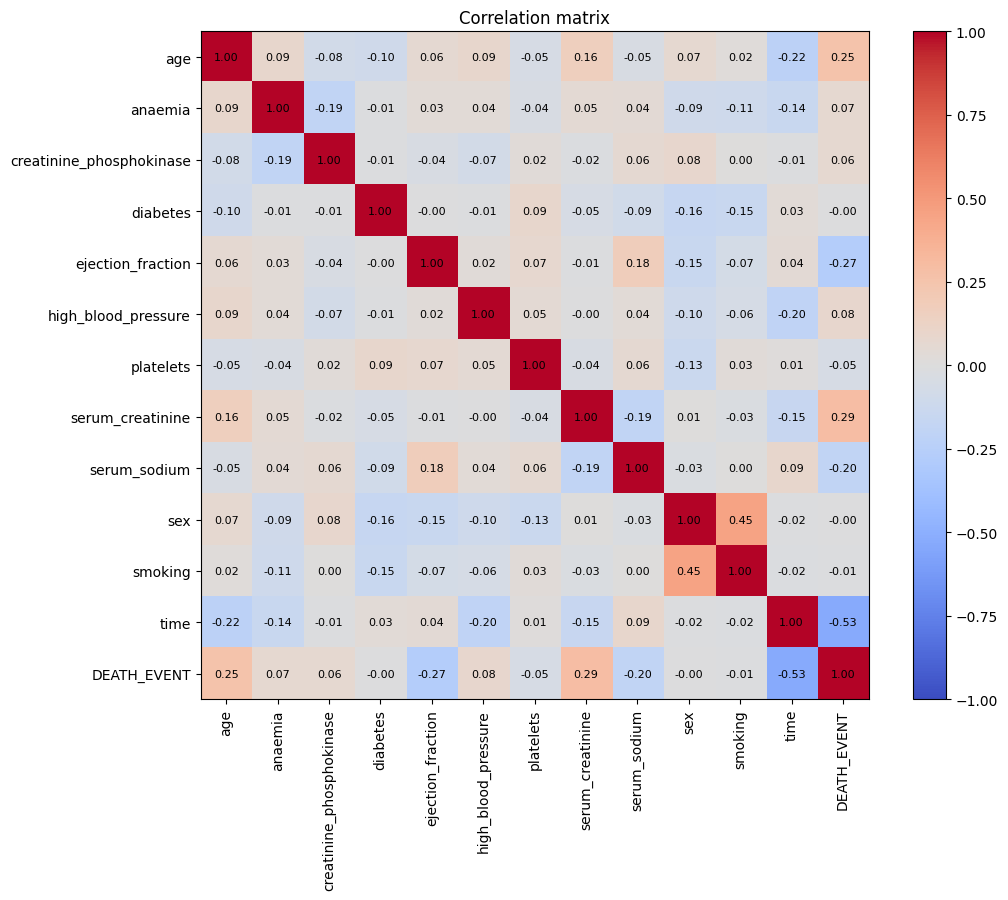

In [13]:
corr = heart.corr(numeric_only=True)

plt.figure(figsize=(11, 9))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)    # red: positive correlation, blue: negative correlation
plt.colorbar()


plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

# heatmap and correlation values
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha='center', va='center', fontsize=8)

plt.title('Correlation matrix')
plt.tight_layout()
plt.show()

Most variables are only weakly correlated with each other 
the strongest link between features is sex and smoking, so men are much more likely to smoke. 

Death is positively correlated with serum creatinine and age , and negatively correlated with ejection fraction and serum sodium . 

Time shows the strongest correlation with death , but this is because follow-up ends when a patient dies, so it is a consequence not a risk factor.



In [14]:
# do a cross table
smoke_sex = pd.crosstab(heart['sex'], heart['smoking'])

# change names
smoke_sex.index = ['Female', 'Male']
smoke_sex.columns = ['Non-smoker', 'Smoker']
smoke_sex

,Non-smoker,Smoker
Female,101,4
Male,102,92


In [15]:
# calculate rate of smoker for each gender
sex_names = ['Female', 'Male']

for sex_value in [0, 1]:  # 0 = Female, 1 = Male
    group = heart[heart['sex'] == sex_value]
    nb_total = len(group)  # total number of people of this gender
    nb_smoker = group['smoking'].sum()  # number of smokers (0/1 sum)
    percent_smoker = nb_smoker / nb_total

    print(f"{sex_names[sex_value]}: {nb_smoker} smokers out of {nb_total} ({percent_smoker:.1%})")

Female: 4 smokers out of 105 (3.8%)
Male: 92 smokers out of 194 (47.4%)


### Chi-square test

The chi-square test  is used to test whether two categorical variables are independent:
- **H0**: Smoking and sex are not related.
- **H1 (alternative hypothesis)**: Smoking and sex are related.
- If the **p-value < 0.05**, reject H0, so the proportion of smokers is significantly different between men and women.

In [16]:
chi2, p_value, dof, expected = stats.chi2_contingency(smoke_sex)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"p-value: {p_value:.2e}")    

if p_value < 0.05:
    print("smoking distribution is different between genders")
else:
    print("no significant difference")

Chi-square statistic: 57.46
p-value: 3.44e-14
smoking distribution is different between genders


## Q5. How many patients have each combination of underlying conditions? 

3 underlying conditions：anaemia , diabetes , high_blood_pressure.

there are 8 combinations



In [17]:
def condition_label(row):
    '''
    This function takes one patient and returns
    the combination of underlying conditions as a string.
    '''
    conditions = []
    if row['anaemia'] == 1:
        conditions.append('Anaemia')
    if row['diabetes'] == 1:
        conditions.append('Diabetes')
    if row['high_blood_pressure'] == 1:
        conditions.append('High BP')

    if not conditions:
        return 'None'
    return ' and '.join(conditions)    

In [18]:
# give each patient a label for their underlying conditions
condition_labels = []
for row_index, row in heart.iterrows():    
    condition_labels.append(condition_label(row))

heart['conditions'] = condition_labels
heart[['conditions']].head(10)

,conditions
0,High BP
1,None
2,None
3,Anaemia
4,Anaemia and Diabetes
5,Anaemia and High BP
6,Anaemia
7,Anaemia and Diabetes
8,None
9,Anaemia and High BP


In [19]:
# count
combination_counts = heart['conditions'].value_counts()

for combination in combination_counts.index:
    count = combination_counts[combination]      # count of patients with this combination
    percentage = count / total          # proportion 
    print(f"{combination}: {count} patients ({percentage:.1%})")

None: 67 patients (22.4%)
Diabetes: 46 patients (15.4%)
Anaemia: 45 patients (15.1%)
Anaemia and Diabetes: 36 patients (12.0%)
High BP: 31 patients (10.4%)
Anaemia and High BP: 31 patients (10.4%)
Diabetes and High BP: 26 patients (8.7%)
Anaemia and Diabetes and High BP: 17 patients (5.7%)


Only about 22% of patients have none of the three conditions, so nearly 4 out of 5 heart failure patients have at least one underlying condition.

## Q6. Further analysis 

This section contains two additional analyses:
1. **Is smoking related to death?** 

2. **When do deaths happen?** 

### 6.1 Smoking, sex and death

Q4 showed that the proportion of smokers is much higher among men than among women. So if we simply compare smokers and non-smokers, the effect of smoking and the effect of sex are mixed together.

so we stratify by sex. 

We first look at all patients, then at women and men separately. If smoking really affects death, we should also see a difference within the same sex.

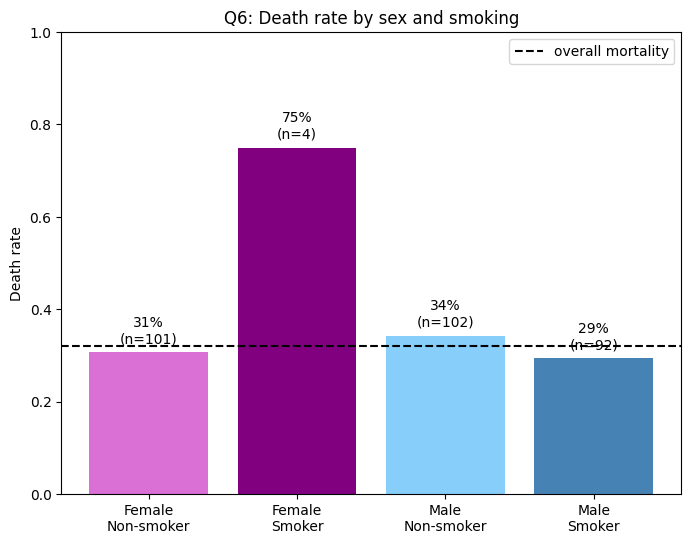

In [20]:
# death rate for each combination of sex and smoking
group_names = []
death_rates = []
group_sizes = []

for sex_value in [0, 1]:
    for smoking_value in [0, 1]:
        same_sex = heart['sex'] == sex_value
        same_smoking = heart['smoking'] == smoking_value
        group = heart[same_sex & same_smoking]

        sex_name = ['Female', 'Male'][sex_value]
        smoking_name = ['Non-smoker', 'Smoker'][smoking_value]
        group_names.append(f"{sex_name}\n{smoking_name}")

        death_rates.append(group['DEATH_EVENT'].mean())
        group_sizes.append(len(group))

plt.figure(figsize=(8, 6))
plt.bar(group_names, death_rates, color=['orchid', 'purple', 'lightskyblue', 'steelblue'])
plt.axhline(mortality_rate, color='black', linestyle='--', label='overall mortality')

for group_index in range(len(group_names)):
    death_rate = death_rates[group_index]
    group_size = group_sizes[group_index]
    label = f"{death_rate:.0%}\n(n={group_size})"
    plt.text(group_index, death_rate + 0.02, label, ha='center')

plt.ylabel('Death rate')
plt.ylim(0, 1)
plt.title('Q6: Death rate by sex and smoking')
plt.legend()
plt.show()

**All patients**: smokers and non-smokers have almost the same death rate (31% vs 33%, p = 0.93).

**Men**: the death rates are also similar .

**Women**: the number was large at 75%, but there are only 4 smokers, too few to draw a conclusion.

So smoking is not a risk factor for death, even when we look at men and women separately.


### 6.2 When do deaths happen?

time is the follow-up period in days. For patients who died, time is **the day of follow-up on which they died**.
We look only at the 96 patients who died and count how many of them died within the first 30, 60 and 90 days.

Deaths within 30 days: 35 / 96 (36.5%)
Deaths within 60 days: 54 / 96 (56.2%)
Deaths within 90 days: 69 / 96 (71.9%)

Median follow-up time (Survived): 172.0 days
Median follow-up time (Died): 44.5 days


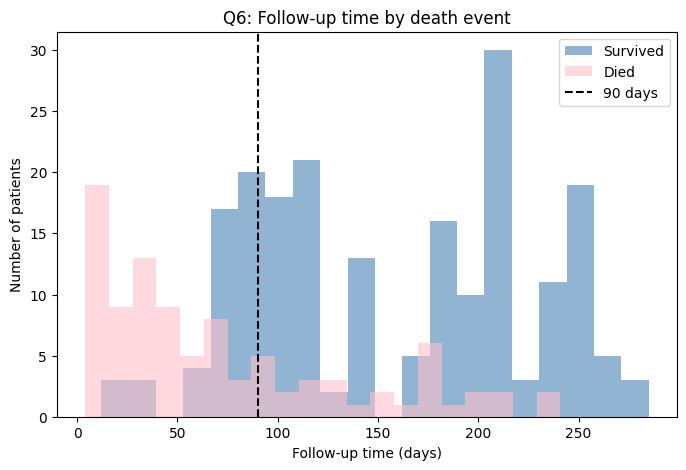

In [21]:
# when do deaths happen?
death_count = len(died)

for days in [30, 60, 90]:
    early_death_count = (died['time'] <= days).sum()
    early_death_percentage = early_death_count / death_count
    print(f"Deaths within {days} days: {early_death_count} / {death_count} ({early_death_percentage:.1%})")

print(f"\nMedian follow-up time (Survived): {survived['time'].median()} days")
print(f"Median follow-up time (Died): {died['time'].median()} days")

# compare follow-up time of survived and died patients
plt.figure(figsize=(8, 5))
plt.hist(survived['time'], bins=20, alpha=0.6, color='steelblue', label='Survived')
plt.hist(died['time'], bins=20, alpha=0.6, color='pink', label='Died')
plt.axvline(90, color='black', linestyle='--', label='90 days')
plt.xlabel('Follow-up time (days)')
plt.ylabel('Number of patients')
plt.title('Q6: Follow-up time by death event')
plt.legend()
plt.show()


Most deaths happen early: 72% of deaths occur within the first 90 days 
So patients should be closely monitored in the first three months.

And from this we can also conclude that `time` is not a risk factor. Because follow-up ends when a patient dies,  a short follow-up time is a result of death, not a cause. 

## Q7. What are the main factors associated with a higher risk?

We use statistical test to check whether the differences between the survived group and the died group are significant.

**Continuous variables: t-test**
H0: the survived group and the died group have the same mean

If p < 0.05, the means of the two groups are significantly different, so this variable is related to death

**Binary variables: chi-square test**
H0: this variable is not related to death

If p < 0.05, it is related to death


In [22]:
# continuous variables: compare survived and died patients
continuous_rows = []

for column in continuous_cols:
    if column == 'time':    # go across time
        continue

    survived_values = survived[column]
    died_values = died[column]
    t_statistic, p_value = stats.ttest_ind(survived_values, died_values, equal_var=False)  # Welch's t-test

    survived_mean = survived_values.mean()
    survived_standard_deviation = survived_values.std()
    died_mean = died_values.mean()
    died_standard_deviation = died_values.std()

    row = {
        'variable': column,
        'survived_mean (SD)': f"{survived_mean:.2f} ({survived_standard_deviation:.2f})",
        'died_mean (SD)': f"{died_mean:.2f} ({died_standard_deviation:.2f})",
        'p_value': round(p_value, 4),
        'significant': 'Yes' if p_value < 0.05 else 'No'
    }
    continuous_rows.append(row)

continuous_result = pd.DataFrame(continuous_rows).sort_values('p_value')
continuous_result

,variable,survived_mean (SD),died_mean (SD),p_value,significant
0,age,58.76 (10.64),65.22 (13.21),0.0000,Yes
2,ejection_fraction,40.27 (10.86),33.47 (12.53),0.0000,Yes
4,serum_creatinine,1.18 (0.65),1.84 (1.47),0.0001,Yes
5,serum_sodium,137.22 (3.98),135.38 (5.00),0.0019,Yes
1,creatinine_phosphokinase,540.05 (753.80),670.20 (1316.58),0.3692,No
3,platelets,266657.49 (97531.20),256381.04 (98525.68),0.3993,No


In [23]:
# binary variables: compare survived and died patients
binary_rows = []

for column in binary_cols:
    table = pd.crosstab(heart[column], heart['DEATH_EVENT'])
    chi_square, p_value, degrees_of_freedom, expected = stats.chi2_contingency(table)

    group_zero = heart[heart[column] == 0]
    group_one = heart[heart[column] == 1]
    death_rate_0 = group_zero['DEATH_EVENT'].mean()
    death_rate_1 = group_one['DEATH_EVENT'].mean()

    row = {
        'variable': column,
        'death_rate if 0': round(death_rate_0, 3),
        'death_rate if 1': round(death_rate_1, 3),
        'p_value': round(p_value, 4),
        'significant': 'Yes' if p_value < 0.05 else 'No'
    }
    binary_rows.append(row)

binary_result = pd.DataFrame(binary_rows).sort_values('p_value')
binary_result

,variable,death_rate if 0,death_rate if 1,p_value,significant
2,high_blood_pressure,0.294,0.371,0.2141,No
0,anaemia,0.294,0.357,0.3073,No
4,smoking,0.325,0.312,0.9318,No
1,diabetes,0.322,0.320,1.0000,No
3,sex,0.324,0.320,1.0000,No



**Significant** (p < 0.05): patients who died had a lower ejection fraction, higher serum creatinine, were older and had lower serum sodium.

**Not significant**: creatinine phosphokinase, platelets, anaemia, diabetes, high blood pressure, sex and smoking.

So the main risk factors are low ejection fraction, high serum creatinine and older age, followed by low serum sodium. in conclusion, heart function, kidney function and age matter most.

## Q8 (Optional). Classification model

**Goal**: predict whether a patient will die from their features.

**Models**:
1. KNN(not good)
2. Logistic regression
3. Logistic regression with oversampling


 `time` is not used, and neither is the `conditions` column created in Q5.

In [24]:
# select features
features = ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction',
            'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking']
target = 'DEATH_EVENT'

patient_features = heart[features]
death_labels = heart[target]

print(f"X shape: {patient_features.shape}")
print(death_labels.value_counts())

X shape: (299, 11)
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64


In [25]:
# learning set (80%) and test set (20%)
learning_features, test_features, learning_labels, test_labels = train_test_split(
    patient_features, death_labels, test_size=0.2, random_state=0, stratify=death_labels  # keep same death rate
)

# learning set :training set (70%) and validation set (10%)
training_features, validation_features, training_labels, validation_labels = train_test_split(
    learning_features, learning_labels, test_size=0.125, random_state=0, stratify=learning_labels
)

print(f"Training set size: {training_features.shape[0]}")
print(f"Validation set size: {validation_features.shape[0]}")
print(f"Test set size: {test_features.shape[0]}")

Training set size: 209
Validation set size: 30
Test set size: 60


In [26]:
baseline_accuracy = (test_labels == 0).mean()
print(f"Baseline accuracy: {baseline_accuracy:.4f}")

Baseline accuracy: 0.6833


### Model 1: KNN

**Method**: to predict a new patient, KNN finds the k most similar patients in the training set and takes the majority class.

**Why**:
- It is a simple model that makes no assumption about the data.
- KNN uses distances, so the variables must be standardized first.
- We only try odd values like 1, 3, ..., 31 to avoid ties, and choose k on the validation set.

In [27]:
neighbor_counts = range(1, 33, 2)
training_accuracies = []
validation_accuracies = []

for neighbor_count in neighbor_counts:
    nearest_neighbors_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=neighbor_count))
    nearest_neighbors_model.fit(training_features, training_labels)  # train on the training set
    training_predictions = nearest_neighbors_model.predict(training_features)
    validation_predictions = nearest_neighbors_model.predict(validation_features)
    training_accuracy = accuracy_score(training_labels, training_predictions)
    validation_accuracy = accuracy_score(validation_labels, validation_predictions)  # evaluate on the validation set
    training_accuracies.append(training_accuracy)
    validation_accuracies.append(validation_accuracy)
    print(f"k={neighbor_count}: train accuracy = {training_accuracy:.4f}, validation accuracy = {validation_accuracy:.4f}")

# the best k 
best_neighbor_count = neighbor_counts[np.argmax(validation_accuracies)]
print(f"Best k: {best_neighbor_count}")

k=1: train accuracy = 1.0000, validation accuracy = 0.4000
k=3: train accuracy = 0.8325, validation accuracy = 0.6000
k=5: train accuracy = 0.7656, validation accuracy = 0.6667
k=7: train accuracy = 0.7225, validation accuracy = 0.7667
k=9: train accuracy = 0.6986, validation accuracy = 0.7667
k=11: train accuracy = 0.7225, validation accuracy = 0.7667
k=13: train accuracy = 0.7129, validation accuracy = 0.7667
k=15: train accuracy = 0.7033, validation accuracy = 0.7667
k=17: train accuracy = 0.6938, validation accuracy = 0.7000
k=19: train accuracy = 0.6986, validation accuracy = 0.6667
k=21: train accuracy = 0.6938, validation accuracy = 0.6667
k=23: train accuracy = 0.6938, validation accuracy = 0.6667
k=25: train accuracy = 0.6938, validation accuracy = 0.6667
k=27: train accuracy = 0.6986, validation accuracy = 0.6667
k=29: train accuracy = 0.6890, validation accuracy = 0.6667
k=31: train accuracy = 0.6890, validation accuracy = 0.6667
Best k: 7


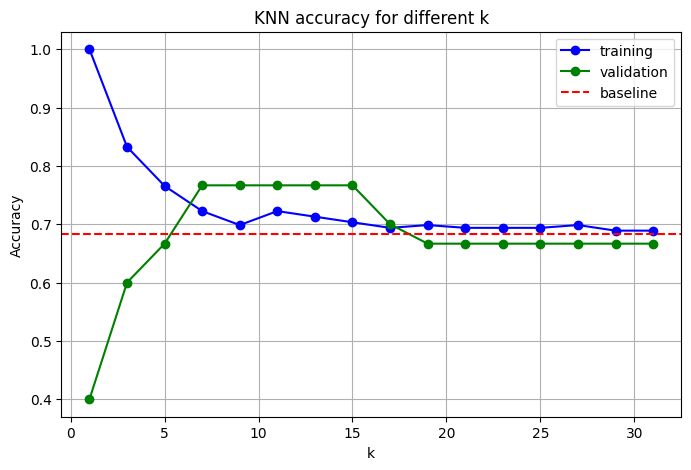

In [28]:
plt.figure(figsize=(8, 5))
plt.plot(neighbor_counts, training_accuracies, 'bo-', label='training')
plt.plot(neighbor_counts, validation_accuracies, 'go-', label='validation')
plt.axhline(baseline_accuracy, color='red', linestyle='--', label='baseline')
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.title('KNN accuracy for different k')
plt.legend()
plt.grid(True)
plt.show()

We retrain the model with the best k on the learning set and evaluate it once on the test set.

Evaluation metrics (computed from the confusion matrix):

 Accuracy = correct predictions / total

 Recall = TP / (TP + FN)

 Precision = TP / (TP + FP)


In [29]:
def evaluate(actual_labels, predicted_labels):
    '''
    This function prints the confusion matrix, accuracy, recall and precision,
    and returns the confusion matrix.
    '''
    confusion_counts = confusion_matrix(actual_labels, predicted_labels)
    true_negatives = confusion_counts[0, 0]
    false_positives = confusion_counts[0, 1]
    false_negatives = confusion_counts[1, 0]
    true_positives = confusion_counts[1, 1]

    print("Confusion Matrix:")
    print(confusion_counts)
    print(f"TN = {true_negatives}, FP = {false_positives}, FN = {false_negatives}, TP = {true_positives}")
    print(f"Accuracy: {(true_positives + true_negatives) / confusion_counts.sum():.4f}")
    print(f"Recall: {true_positives / (true_positives + false_negatives):.4f}")
    print(f"Precision: {true_positives / (true_positives + false_positives):.4f}")
    return confusion_counts

In [30]:
best_nearest_neighbors_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_neighbor_count))
best_nearest_neighbors_model.fit(learning_features, learning_labels)
nearest_neighbors_predictions = best_nearest_neighbors_model.predict(test_features)

nearest_neighbors_confusion_matrix = evaluate(test_labels, nearest_neighbors_predictions)

Confusion Matrix:
[[37  4]
 [16  3]]
TN = 37, FP = 4, FN = 16, TP = 3
Accuracy: 0.6667
Recall: 0.1579
Precision: 0.4286


### Model 2: Logistic regression

**Method**: logistic regression estimates the probability of death. If the probability is above 0.5, the patient is predicted to die.

Its coefficients show whether each variable increases or decreases the risk of death.

The features are standardized first, so that the coefficients can be compared directly.

In [31]:
# standardize: fit the scaler on the learning set only, then apply it to the test set
scaler = StandardScaler()
scaled_learning_features = scaler.fit_transform(learning_features)
scaled_test_features = scaler.transform(test_features)

logistic_regression_model = LogisticRegression(max_iter=1000)
logistic_regression_model.fit(scaled_learning_features, learning_labels)
logistic_regression_predictions = logistic_regression_model.predict(scaled_test_features)

logistic_regression_confusion_matrix = evaluate(test_labels, logistic_regression_predictions)

Confusion Matrix:
[[39  2]
 [11  8]]
TN = 39, FP = 2, FN = 11, TP = 8
Accuracy: 0.7833
Recall: 0.4211
Precision: 0.8000


/Users/zaozao/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/zaozao/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/zaozao/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/zaozao/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/zaozao/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_

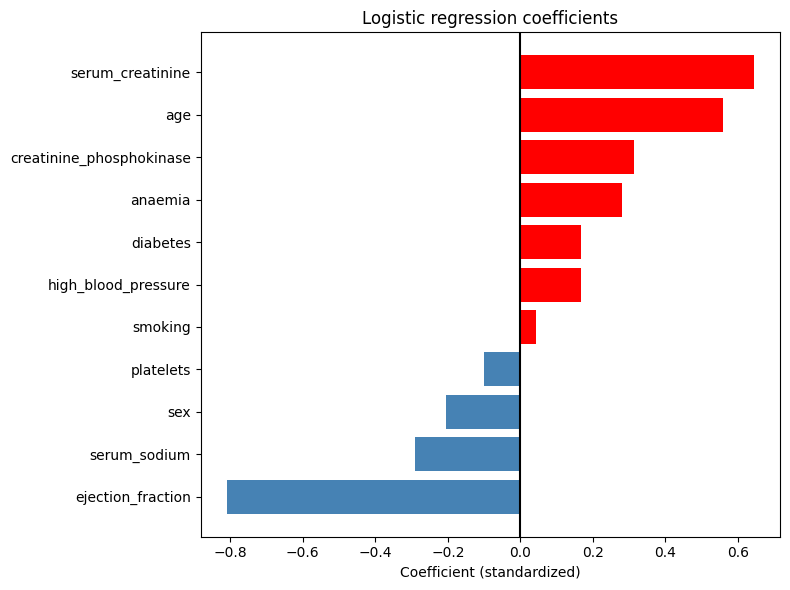

In [32]:
# coefficients: positive = higher risk (red), negative = lower risk (blue)
coefficient_table = pd.DataFrame({'feature': features, 'coefficient': logistic_regression_model.coef_[0]})
coefficient_table = coefficient_table.sort_values('coefficient')

colors = []
for coefficient in coefficient_table['coefficient']:
    if coefficient > 0:
        colors.append('red')
    else:
        colors.append('steelblue')

plt.figure(figsize=(8, 6))
plt.barh(coefficient_table['feature'], coefficient_table['coefficient'], color=colors)
plt.axvline(0, color='black')
plt.xlabel('Coefficient (standardized)')
plt.title('Logistic regression coefficients')
plt.tight_layout()
plt.show()

On the test set, accuracy is 78%, the highest of the three models, and precision is 80%.

But only 8 of the 19 deaths are found (recall 42%):  many missed deaths.

The largest coefficients are ejection fraction, serum creatinine and age.

### Model 3: Logistic regression with oversampling

**Method**

We randomly duplicated records of patients who died in training set until both groups were the same size. Then retrained the same logistic regression model.

**Why**

The earlier models missed more than half of the deaths. 

There were twice as many survivors as deaths, so the models tended to predict survival.

Balancing the training set can help the model detect more deaths. 
 
We kept the original class balance in the test set for a realistic evaluation.

In [33]:
# put X and Y together to split the learning set into survived and died
learning_data = learning_features.copy()
learning_data['DEATH_EVENT'] = learning_labels

learning_survivors = learning_data[learning_data['DEATH_EVENT'] == 0]
learning_deaths = learning_data[learning_data['DEATH_EVENT'] == 1]
print(f"Before oversampling: survived = {len(learning_survivors)}, died = {len(learning_deaths)}")

# randomly copy patients who died 
extra_death_count = len(learning_survivors) - len(learning_deaths)
extra_death_rows = learning_deaths.sample(n=extra_death_count, replace=True, random_state=0)

oversampled_learning_data = pd.concat([learning_survivors, learning_deaths, extra_death_rows])
oversampled_learning_features = oversampled_learning_data[features]
oversampled_learning_labels = oversampled_learning_data['DEATH_EVENT']

print(f"After oversampling: survived = {(oversampled_learning_labels == 0).sum()}, died = {(oversampled_learning_labels == 1).sum()}")

Before oversampling: survived = 162, died = 77
After oversampling: survived = 162, died = 162


In [34]:
# train on the oversampled data
scaled_oversampled_learning_features = scaler.transform(oversampled_learning_features)

oversampled_logistic_model = LogisticRegression(max_iter=1000)
oversampled_logistic_model.fit(scaled_oversampled_learning_features, oversampled_learning_labels)
oversampled_predictions = oversampled_logistic_model.predict(scaled_test_features)    # evaluated on the original test set

oversampled_confusion_matrix = evaluate(test_labels, oversampled_predictions)

Confusion Matrix:
[[33  8]
 [ 7 12]]
TN = 33, FP = 8, FN = 7, TP = 12
Accuracy: 0.7500
Recall: 0.6316
Precision: 0.6000


/Users/zaozao/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/zaozao/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/zaozao/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/zaozao/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/zaozao/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_

### Model comparison

Besides accuracy, we look at recall, F1 and missed deaths (FN), because missing a patient who will die is the most serious error.

F1 = 2 × precision × recall / (precision + recall): it is high only if both precision and recall are high.

the baseline has an accuracy of 68.3% .

In [35]:
# compute the metrics of each model from its confusion matrix
models = [
    [f'KNN (k={best_neighbor_count})', nearest_neighbors_confusion_matrix],
    ['Logistic regression', logistic_regression_confusion_matrix],
    ['Logistic regression + oversampling', oversampled_confusion_matrix]
]

rows = []
for name, confusion_counts in models:
    true_negatives = confusion_counts[0, 0]
    false_positives = confusion_counts[0, 1]
    false_negatives = confusion_counts[1, 0]
    true_positives = confusion_counts[1, 1]

    accuracy = (true_positives + true_negatives) / confusion_counts.sum()
    recall = true_positives / (true_positives + false_negatives)
    precision = true_positives / (true_positives + false_positives)
    f1_score = 2 * precision * recall / (precision + recall)

    row = {
        'model': name,
        'accuracy': round(accuracy, 4),
        'recall': round(recall, 4),
        'precision': round(precision, 4),
        'F1': round(f1_score, 4),
        'missed deaths (FN)': false_negatives,
        'false alarms (FP)': false_positives
    }
    rows.append(row)

model_comparison = pd.DataFrame(rows)
model_comparison

,model,accuracy,recall,precision,F1,missed deaths (FN),false alarms (FP)
0,KNN (k=7),0.6667,0.1579,0.4286,0.2308,16,4
1,Logistic regression,0.7833,0.4211,0.8000,0.5517,11,2
2,Logistic regression + oversampling,0.7500,0.6316,0.6000,0.6154,7,8


KNN is worse than the baseline.

Logistic regression has the highest accuracy 78% but missed 11 of 19 deaths.

Logistic regression with oversampling was the best model for screening. It has the highest F1 score, misses the fewest deaths, and has 75% accuracy.
